## Initiate the model

In [40]:
# enter creedencials

import os
import boto3

def parse_env_credentials(filepath):
    """
    Parses AWS credentials from a text file with KEY=VALUE format.
    
    Args:
        filepath: Path to the credentials file (e.g., 'credentials.txt' or '.env').
        
    Returns:
        dict: A dictionary ready to be unpacked into boto3.client/resource,
              or None if parsing fails.
    """
    creds = {}
    
    try:
        with open(filepath, 'r', encoding='utf-8') as f:
            for line in f:
                # Skip empty lines or comments
                line = line.strip()
                if not line or line.startswith('#'):
                    continue
                
                if '=' in line:
                    key, value = line.split('=', 1)
                    key = key.strip()
                    value = value.strip()
                    
                    # Map the file keys to boto3 expected arguments
                    if key == 'AWS_REGION':
                        creds['aws_region'] = value
                    elif key == 'AWS_ACCESS_KEY_ID':
                        creds['aws_access_key_id'] = value
                    elif key == 'AWS_SECRET_ACCESS_KEY':
                        creds['aws_secret_access_key'] = value
                    elif key == 'AWS_SESSION_TOKEN': 
                        # Added this just in case your new file uses temporary keys
                        creds['aws_session_token'] = value

        # specific check to ensure we found what we needed
        if 'aws_access_key_id' not in creds:
             print(f"Warning: No AWS_ACCESS_KEY_ID found in {filepath}")
             return None

        return creds

    except FileNotFoundError:
        print(f"Error: File '{filepath}' not found.")
        return None
    except Exception as e:
        print(f"Error parsing file: {e}")
        return None



# 1. Point to your local file (e.g., "credentials.json")
file_path = "./credentials.json"

# 2. Parse
credentials = parse_env_credentials(file_path)

if credentials:
    print("Credentials parsed successfully!")
    print(f"Region: {credentials.get('aws_region')}")
    
    # 3. Use with Boto3 (Unpacking the dict automatically)
    
    
    bedrock_client = boto3.client(
        service_name='bedrock-runtime',
        aws_access_key_id=credentials['aws_access_key_id'],
        aws_secret_access_key=credentials['aws_secret_access_key'],
        # IMPORTANT: boto3 expects the argument 'region_name', so we map 'aws_region' to it
        region_name=credentials['aws_region']
    )
    
    # 3. Test (Optional print to verify)
    print(f"Client created for region: {credentials['aws_region']}")
    # The **credentials syntax automatically expands the dict into arguments:
    # aws_access_key_id=..., aws_secret_access_key=..., region_name=...

Credentials parsed successfully!
Region: us-east-2
Client created for region: us-east-2


In [41]:
#@title Model availabitity etc
#@markdown `On demand` means you can use it.
# Initialize the boto3 client for Bedrock
bedrock_client = boto3.client(
    'bedrock',
    aws_access_key_id=credentials['aws_access_key_id'],
    aws_secret_access_key=credentials['aws_secret_access_key'],
    region_name=credentials['aws_region']
)
bedrock_client.list_foundation_models()['modelSummaries']

[{'modelArn': 'arn:aws:bedrock:us-east-2::foundation-model/openai.gpt-6-astra',
  'modelId': 'openai.gpt-6-astra',
  'modelName': 'GPT-6 Astra',
  'providerName': 'OpenAI',
  'inputModalities': ['TEXT', 'IMAGE'],
  'outputModalities': ['TEXT'],
  'responseStreamingSupported': True,
  'customizationsSupported': [],
  'inferenceTypesSupported': ['INFERENCE_PROFILE'],
  'modelLifecycle': {'status': 'ACTIVE',
   'startOfLifeTime': datetime.datetime(2026, 9, 8, 17, 0, tzinfo=tzutc())}},
 {'modelArn': 'arn:aws:bedrock:us-east-2::foundation-model/nvidia.nemotron-nano-12b-v2',
  'modelId': 'nvidia.nemotron-nano-12b-v2',
  'modelName': 'NVIDIA Nemotron Nano 12B v2 VL BF16',
  'providerName': 'NVIDIA',
  'inputModalities': ['TEXT', 'IMAGE'],
  'outputModalities': ['TEXT'],
  'responseStreamingSupported': True,
  'customizationsSupported': [],
  'inferenceTypesSupported': ['ON_DEMAND'],
  'modelLifecycle': {'status': 'ACTIVE',
   'startOfLifeTime': datetime.datetime(2025, 12, 2, 0, 0, tzinfo=tzut

In [42]:
#Create a Bedrock client using the parsed credentials

import boto3
import json
import pandas as pd
from botocore.config import Config
import time


bedrock_runtime = boto3.client(
    service_name='bedrock-runtime',
    aws_access_key_id=credentials['aws_access_key_id'],
    aws_secret_access_key=credentials['aws_secret_access_key'],
    region_name=credentials['aws_region'],
    config=Config(retries={"max_attempts": 10, "mode": "adaptive"})
)

## Extract the Narratives

In [43]:
# --- JSON EXTRACTOR ---
def extract_json_from_model_output(text: str):
    """Extracts the outermost JSON object from LLM output, ignoring reasoning tags."""
    if not text or not isinstance(text, str):
        return None

    # 1. Remove DeepSeek's reasoning block completely
    text = re.sub(r"<think>.*?</think>", "", text, flags=re.DOTALL)
    
    # 2. Remove markdown code blocks
    text = re.sub(r"```json", "", text, flags=re.IGNORECASE)
    text = re.sub(r"```", "", text)
    
    # 3. Find outermost curly braces to capture nested arrays safely
    start = text.find('{')
    end = text.rfind('}')
    
    if start != -1 and end != -1 and end > start:
        candidate = text[start:end+1]
        try:
            return json.loads(candidate)
        except Exception:
            pass
            
    return None

In [ ]:
import os
import re
import time
import json
import pandas as pd


# 1. Load raw paragraphs data
df_raw = pd.read_csv('./out_files/01_paragraphs_clean.csv')

os.makedirs('./llm_full_pipeline', exist_ok=True)
os.makedirs('./llm_full_pipeline/deepseek_r1', exist_ok=True)
extracted_records = []

# --- BATCH / TEST SETTINGS ---
BATCH_SIZE = 20
MAX_BATCHES = None

print(f"Starting run: processing {MAX_BATCHES if MAX_BATCHES else 'all'} batches ({BATCH_SIZE} paragraphs/batch)...")

def chunk_dataframe(df, batch_size):
    for i in range(0, len(df), batch_size):
        yield df.iloc[i:i + batch_size]

for batch_idx, batch_df in enumerate(chunk_dataframe(df_raw, BATCH_SIZE)):
    
    # Stop condition for test check
    if MAX_BATCHES is not None and batch_idx >= MAX_BATCHES:
        print(f"\nReached check limit of {MAX_BATCHES} batches. Stopping loop.")
        break
    
    # Format batch items preserving original fields
    batch_items_text = []
    valid_ids = []
    
    for idx, row in batch_df.iterrows():
        paragraph_text = str(row.get('paragraph', '')).strip()
        sitting_date = str(row.get('sitting_date', 'Unknown')).strip()
        political_party = str(row.get('party', 'Unknown')).strip()
        
        if len(paragraph_text) >= 15:
            valid_ids.append(idx)
            item_block = f"""--- Item id: {idx} ---
sitting_date: 
{sitting_date}
political_party: 
{political_party}
paragraph: 
{paragraph_text}"""
            batch_items_text.append(item_block)
            
    if not batch_items_text:
        continue 

    all_items_str = "\n\n".join(batch_items_text)
    num_items = len(batch_items_text)

    # Restored original prompt instructions and phrasing
    prompt_extract = f"""Act like a senior political discourse analyst and annotation specialist.
Objective:
Read Greek parliamentary paragraphs and output each narrative as a single, standalone sentence (or "irrelevant" if off-topic) in strict JSON. Do not add any extra text.

You receive a batch of {num_items} items below:
{all_items_str}

Task:
For each item, produce one concise narrative that captures the core position/claim about the Tempi train crash (Greece, 2023) or return "irrelevant".

Requirements:
1) Work primarily from the paragraph text; use metadata solely for light contextual disambiguation.
2) If the paragraph does not substantively concern the crash or its direct implications, output "irrelevant".
3) Output must be a direct, declarative proposition of the core claim, causal argument, or policy thrust—not a meta-summary of what was said.
4) Strictly avoid attribution frames and paragraph-reporting verbs: do not begin with or include phrases like “the speaker…”, “the opposition…”, “is accused…”, “criticizes…”, “argues…”, “says…”, or use “the government…” as a reporting subject (institutional critiques of state/government action or policy are permitted as direct propositions).
5) No quotes, slogans, rhetorical questions, lists, or multiple sentences.
6) ≤ 15 words. English only. Plain text. No names, no hashtags, no emojis.

Process (apply sequentially to each item):
1) Check topicality against the Tempi crash and immediate accountability, investigation, safety, governance, or legal ramifications.
2) If off-topic, set result to "irrelevant".
3) If on-topic, distill the central position/claim into a concise proposition or causal/prescriptive statement without any source attribution.
4) Compress and normalize wording for clarity and specificity; prefer concrete policy or accountability thrusts over narrative “who said what”.
5) Validate constraints: one sentence, ≤ 15 words, English, no attribution/meta-intros, no filler.

Output format (return this JSON containing all {num_items} items and nothing else):
{{
  "results": [
    {{
      "id": <item_id>,
      "narrative": "your one-sentence result here or the exact word irrelevant"
    }}
  ]
}}

Self-check before returning:
- On-topic? If not, output "irrelevant".
- No attribution/meta-intros or paragraph-reporting verbs.
- Exactly one sentence, ≤ 15 words, valid JSON only.
Take a deep breath and work on this problem step-by-step"""

    try:
        response = bedrock_runtime.converse(
            modelId="us.deepseek.r1-v1:0",
            messages=[{"role": "user", "content": [{"text": prompt_extract}]}],
            inferenceConfig={"maxTokens": 8192}
        )

        model_reply = response["output"]["message"]["content"][0]["text"]
        parsed = extract_json_from_model_output(model_reply)

        if parsed and isinstance(parsed, dict) and "results" in parsed:
            results_array = parsed["results"]
            
            for res in results_array:
                orig_id = res.get("id")
                narrative_val = str(res.get("narrative", "")).strip()
                cleaned_val = narrative_val.strip(" .\"'").lower()
                
                if orig_id in df_raw.index:
                    orig_row = df_raw.loc[orig_id]
                    
                    if cleaned_val != "irrelevant":
                        extracted_records.append({
                            "paragraph_id": orig_row.get('paragraph_id', ''),
                            "sitting_date": orig_row.get('sitting_date', 'Unknown'),
                            "political_party": orig_row.get('party', 'Unknown'),
                            "paragraph": orig_row.get('paragraph', ''),
                            "narrative": narrative_val
                        })
            
            valid_count = len([r for r in results_array if str(r.get('narrative')).strip(" .\"'").lower() != 'irrelevant'])
            print(f"Batch {batch_idx + 1} processed ({num_items} paragraphs) -> Found {valid_count} relevant.")
            
        else:
            print(f"Batch {batch_idx + 1} -> JSON parse failure. Raw output snippet:")
            print(model_reply[:300] + "...")

    except Exception as e:
        print(f"Error on Batch {batch_idx + 1}: {e}")

    time.sleep(0.5)

# Save output
df_extracted = pd.DataFrame(extracted_records)
out_path = './llm_full_pipeline/deepseek_r1/01_extracted_narratives_R1.csv'
df_extracted.to_csv(out_path, index=False, encoding='utf-8-sig')

print(f"\nDone! Extracted {len(df_extracted)} relevant narratives to '{out_path}'.")

if not df_extracted.empty:
    print("\n--- Preview of Extracted Narratives ---")
    for _, row in df_extracted.head(5).iterrows():
        print(f"[{row['political_party']}] {row['narrative']}")

## Create the taxonomy

In [ ]:
import os
import json
import re
import time
import pandas as pd

# ==========================================
# 1. LOAD AND PREPARE DATA
# ==========================================
df_extracted = pd.read_csv('./llm_full_pipeline/deepseek_r1/01_extracted_narratives_R1.csv', encoding='utf-8-sig')

# Clean and deduplicate
raw_narratives = df_extracted['narrative'].dropna().tolist()
all_unique_narratives = list(set([n.strip() for n in raw_narratives if n.strip(" .\"'").lower() != "irrelevant"]))

print(f"Total extracted records: {len(df_extracted)}")
print(f"Total UNIQUE narratives: {len(all_unique_narratives)}")

# ==========================================
# 2. HELPER FUNCTIONS
# ==========================================
def extract_json_from_model_output(text: str):
    if not text or not isinstance(text, str):
        return None
    text = re.sub(r"<think>.*?</think>", "", text, flags=re.DOTALL)
    text = re.sub(r"```json", "", text, flags=re.IGNORECASE)
    text = re.sub(r"```", "", text)
    start = text.find('{')
    end = text.rfind('}')
    if start != -1 and end != -1 and end > start:
        candidate = text[start:end+1]
        try:
            return json.loads(candidate)
        except Exception:
            pass
    return None

def chunk_list(lst, n):
    for i in range(0, len(lst), n):
        yield lst[i:i + n]

MAX_RETRIES = 3

# ==========================================
# 3. PROMPTS
# ==========================================
def get_phase1_prompt(item_count, text_block):
    return f"""Act like a senior political discourse analyst and qualitative annotation specialist with expertise in political narratives, interpretive framing, semantic clustering, and systematic qualitative coding.
Your goal is to classify every supplied narrative statement about the Tempi train crash in Greece into distinct Narrative Level 1 groups while preserving the underlying political interpretations expressed in the data.
Task: Analyze the complete set of {item_count} unique narrative statements and group them into coherent Narrative Level 1 groups according to the theoretical framework below.

THEORETICAL FRAMEWORK
A political narrative is a recurring, overt or implicit claim that promotes a particular interpretation of an ongoing political issue.
A narrative statement is a concise claim about the Tempi crash, its causes, responsibility, investigation, or broader political significance.
A Narrative Family is a group of semantically related statements expressing the same substantive underlying interpretive frame. Such a frame may concern causal explanations, attribution of responsibility, intentions, institutional conduct, accountability, proposed solutions, or the broader political significance of the crash.
The purpose of Narrative Level 1 classification is to identify coherent groups of individual statements that express the same underlying political interpretation. Grouping must be based on substantive meaning, not merely shared topics, keywords, actors, institutions, or events.

STEP-BY-STEP INSTRUCTIONS
1. Read all {item_count} statements before forming groups. Treat each statement as an explicit or implicit claim or interpretation, rather than merely a reference to a topic, actor, institution, or event.
2. Identify the central interpretive claim of each statement. Consider what it communicates about causes, responsibility, intentions, institutional conduct, accountability, proposed solutions, and political significance, insofar as these are supported by the statement.
3. Group statements when they express the same substantive underlying interpretation, even when their wording, specificity, emotional tone, explicitness, or named actors differ.
4. Distinguish groups by their central interpretive claims rather than shared keywords. For example, allegations of deliberate obstruction of an investigation differ from claims of institutional incompetence, even though both concern the investigation.
5. Create separate groups for meaningfully different interpretations. Avoid redundant fragmentation of semantically equivalent claims, but do not merge statements that imply different causes, responsibilities, intentions, or political meanings.
6. Base all classifications exclusively on the supplied statements. Do not introduce external assumptions, infer unsupported motives, or impose interpretations that are not grounded in the input. Do not create miscellaneous, residual, or mixed groups.
7. Assign every statement to exactly one group. Preserve each original statement verbatim, including its wording and punctuation. Do not omit, duplicate, paraphrase, or modify any statement.
8. Give each group a distinct, concise, analytical English group name of 4–8 words. Each name must express the group's shared underlying interpretive claim rather than merely identify a topic, actor, institution, or event.
9. Review the complete classification for semantic coherence, distinctness between groups, and unnecessary duplication. Ensure that statements within each group share a defensible interpretive frame and that meaningfully different claims remain separate.

INPUT

<<<NARRATIVES_START
{text_block}
NARRATIVES_END>>>

OUTPUT CONSTRAINTS

Return only one valid JSON object using exactly the following structure, with no additional keys:

{{
  "narrative_groups": [
    {{
      "group_name": "Group Name",
      "narratives": [
        "exact narrative string 1",
        "exact narrative string 2"
      ]
    }}
  ]
}}

Replace the example values with the actual results. The "narrative_groups" field must contain an array of group objects. Each object must contain exactly two keys: "group_name" and "narratives".
The "group_name" value must be a concise, analytical English name of 4–8 words expressing the shared interpretive claim. The "narratives" value must be an array containing the exact original statement strings assigned to that group.

Every input statement must appear exactly once across all groups. Do not include explanations, additional keys, counts, confidence scores, comments, Markdown fences, or any text outside the JSON object. Ensure the output is syntactically valid JSON with correctly escaped strings.

Take a deep breath and work on this problem step-by-step."""


def get_reduce_prompt(item_count, text_block, is_final=False, target_level="Narrative Level 2"):
    if is_final:
        target_instruction = (
            "overarching Narrative Families representing the final taxonomy. "
            "The final taxonomy MUST contain exactly 15 to 20 Narrative Families."
        )
        constraint_rule = """
6. FINAL TAXONOMY SIZE: The final taxonomy must contain between 15 and 20 Narrative Families, inclusive. First identify which groups share the same underlying interpretive claim, then consolidate redundant groups to reach the required range. Prefer semantically justified merges over arbitrary combinations. Never merge fundamentally different interpretations merely to meet the target. If the input's substantive distinctions make the target impossible to achieve without violating the theoretical framework, preserve the distinctions and produce the closest defensible taxonomy rather than inventing unsupported equivalences.
"""
    else:
        target_instruction = (
            f"{target_level} groups. Consolidate semantically equivalent or substantially "
            "overlapping groups, aiming for approximately half the original number "
            "when this can be achieved without losing meaningful interpretive distinctions."
        )
        constraint_rule = ""

    return f"""Act like a senior political discourse analyst and qualitative annotation specialist with expertise in political narratives, interpretive framing, semantic clustering, and hierarchical qualitative coding.
Your goal is to consolidate {item_count} input narrative groups derived from political statements about the Tempi train crash in Greece into {target_instruction}

THEORETICAL FRAMEWORK
A political narrative is a recurring, overt or implicit claim that promotes a particular interpretation of an ongoing political issue.
A narrative statement is a concise claim about the Tempi crash, its causes, responsibility, investigation, or broader political significance.
A narrative family is a group of semantically related statements or narrative groups expressing the same substantive underlying interpretive frame. This frame may concern causal explanations, attribution of responsibility, intentions, institutional conduct, accountability, proposed solutions, or the broader political significance of the crash.
At this consolidation stage, each supplied group represents an existing narrative grouping. Your task is to identify which groups express the same underlying political interpretation and consolidate them into coherent higher-level narrative families. Shared subject matter alone is insufficient justification for merging.

CONTEXT
The Tempi train crash was a fatal train collision near Tempi, Greece, on 28 February 2023. Its political and institutional aftermath includes railway safety, infrastructure, institutional failures, the investigation, accountability, compensation, and ministerial responsibility. Use this context only to interpret the supplied group titles; do not introduce external claims or assumptions.

STEP-BY-STEP INSTRUCTIONS
1. Read every input group title before deciding which groups to merge. Treat each title as a summary of an interpretive claim, not merely a topic, actor, institution, or event.
2. Identify the central underlying claim represented by each group. Consider what the claim implies about causes, responsibility, intentions, institutional conduct, accountability, proposed remedies, and political significance, insofar as these are supported by the input.
3. Compare groups by substantive meaning rather than keyword similarity. Merge groups when they express the same underlying interpretation, even if their wording, specificity, emphasis, or named actors differ.
4. Preserve theoretically meaningful distinctions. For example, allegations of deliberate government obstruction, institutional incompetence, and long-term systemic neglect must remain distinct unless the supplied titles clearly establish that they express the same underlying claim. Groups addressing the same event or institution must not automatically be merged.
5. Avoid both over-fragmentation and over-consolidation. Combine semantically equivalent or genuinely overlapping claims, but do not collapse distinct causal explanations, attributions of responsibility, alleged intentions, or political interpretations into broad topic-based categories.
6. Assign every supplied input group to exactly one resulting narrative family. Preserve each original input title verbatim in the output. Do not omit, duplicate, rename, or rewrite any input title. Do not introduce unsupported interpretations, external assumptions, or miscellaneous categories.
{constraint_rule}
7. Give each resulting narrative family a concise, analytical English title of 4–8 words. Each title must communicate the shared interpretive claim rather than merely naming a topic, actor, institution, or event. Ensure that titles are distinct, consistent, and nonredundant.
8. Before responding, audit the taxonomy for semantic coherence, complete assignment, exact preservation of input titles, and unnecessary duplication. Confirm that every merge is defensible under the theoretical framework and that no distinct interpretive claim has been erased merely to reduce the number of groups.

INPUT GROUPS

<<<GROUPS_START
{text_block}
GROUPS_END>>>

OUTPUT CONSTRAINTS

Return only one valid JSON object using exactly the following structure, with no additional keys:

{{
  "narrative_groups": [
    {{
      "title": "Group Name",
      "merged_items": ["Exact Input Group 1", "Exact Input Group 2"]
    }}
  ]
}}

Replace the example values with the actual results. The "title" field must contain a 4–8-word analytical English label for the resulting narrative family. The "merged_items" field must contain an array of exact original input group titles assigned to that family.
Every input group must appear exactly once across all "merged_items" arrays. Do not include explanations, comments, counts, confidence scores, Markdown fences, or text outside the JSON object. Ensure the output is syntactically valid JSON with correctly escaped strings.
Take a deep breath and work on this problem step-by-step.
"""

# ==========================================
# 4. PHASE 1: MICRO-BATCH PROCESSING (MAP)
# ==========================================
CHUNK_SIZE_PHASE_1 = 20
narrative_to_level1 = {}
level1_groups = set()

chunks_p1 = list(chunk_list(all_unique_narratives, CHUNK_SIZE_PHASE_1))
print(f"\nPhase 1: Processing {len(chunks_p1)} chunks of ~{CHUNK_SIZE_PHASE_1} narratives to find Narrative Level 1 groups...")

for chunk_idx, chunk in enumerate(chunks_p1):
    print(f"Processing chunk {chunk_idx + 1}/{len(chunks_p1)}...")
    chunk_text = "\n".join([f"- {text}" for text in chunk])
    prompt_chunk = get_phase1_prompt(len(chunk), chunk_text)
    
    success = False
    for attempt in range(MAX_RETRIES):
        try:
            response = bedrock_runtime.converse(
                modelId="us.deepseek.r1-v1:0", 
                messages=[{"role": "user", "content": [{"text": prompt_chunk}]}],
                inferenceConfig={"maxTokens": 8192}
            )
            
            content_blocks = response.get("output", {}).get("message", {}).get("content", [])
            if not content_blocks or "text" not in content_blocks[0]:
                stop_reason = response.get("stopReason", "Unknown API failure")
                raise ValueError(f"Bedrock returned no text. Stop reason: {stop_reason}")
                
            model_reply = content_blocks[0]["text"]
            parsed = extract_json_from_model_output(model_reply)
            
            if parsed and "narrative_groups" in parsed:
                for group in parsed["narrative_groups"]:
                    title = group.get("group_name", "Uncategorized").strip()
                    level1_groups.add(title)
                    for narr in group.get("narratives", []):
                        narrative_to_level1[narr.strip()] = title
                print(f"  -> Found {len(parsed['narrative_groups'])} Narrative Level 1 groups.")
                success = True
                break 
            else:
                print(f"  -> Attempt {attempt + 1} failed to parse JSON. Retrying...")
                
        except Exception as e:
            print(f"  -> Error on chunk {chunk_idx + 1}, attempt {attempt + 1}: {e}")
        
        if not success:
            time.sleep(2) 
            
    if not success:
        print(f"  -> CRITICAL: Chunk {chunk_idx + 1} completely failed after {MAX_RETRIES} attempts.")
        
    time.sleep(1)

level1_groups = list(level1_groups)
print(f"\nPhase 1 Complete. Found {len(level1_groups)} unique Narrative Level 1 groups.")



Total extracted records: 10686
Total UNIQUE narratives: 10647

Phase 1: Processing 533 chunks of ~20 narratives to find Narrative Level 1 groups...
Processing chunk 1/533...
  -> Found 5 Narrative Level 1 groups.
Processing chunk 2/533...
  -> Found 6 Narrative Level 1 groups.
Processing chunk 3/533...
  -> Found 6 Narrative Level 1 groups.
Processing chunk 4/533...
  -> Found 7 Narrative Level 1 groups.
Processing chunk 5/533...
  -> Found 7 Narrative Level 1 groups.
Processing chunk 6/533...
  -> Found 5 Narrative Level 1 groups.
Processing chunk 7/533...
  -> Found 8 Narrative Level 1 groups.
Processing chunk 8/533...
  -> Found 8 Narrative Level 1 groups.
Processing chunk 9/533...
  -> Found 8 Narrative Level 1 groups.
Processing chunk 10/533...
  -> Found 8 Narrative Level 1 groups.
Processing chunk 11/533...
  -> Found 6 Narrative Level 1 groups.
Processing chunk 12/533...
  -> Found 7 Narrative Level 1 groups.
Processing chunk 13/533...
  -> Found 10 Narrative Level 1 groups.
Pr

In [ ]:

# ==========================================
# 5. PHASE 2: DYNAMIC RECURSIVE REDUCE
# ==========================================
print(f"\nPhase 2: Starting recursive reduction of {len(level1_groups)} Narrative Level 1 groups...")

PHASE2_CHUNK_SIZE = 150
hierarchy_map = {}  
current_groups = list(level1_groups)

level = 1
# Keep looping and reducing until the list is small enough for a final pass
while len(current_groups) > 120:
    target_level_name = f"Narrative Level {level + 1}"
    print(f"\n--- Phase 2 (Level {level}): Reducing {len(current_groups)} groups into {target_level_name} ---")
    next_level_groups = set()
    chunks_p2 = list(chunk_list(current_groups, PHASE2_CHUNK_SIZE))
    
    for idx, chunk in enumerate(chunks_p2):
        print(f"Reducing chunk {idx + 1}/{len(chunks_p2)} ({len(chunk)} groups)...")
        batch_text = "\n".join([f"- {c}" for c in chunk])
        
        prompt = get_reduce_prompt(len(chunk), batch_text, is_final=False, target_level=target_level_name)
        
        success = False
        for attempt in range(MAX_RETRIES):
            try:
                response = bedrock_runtime.converse(
                    modelId="us.deepseek.r1-v1:0", 
                    messages=[{"role": "user", "content": [{"text": prompt}]}],
                    inferenceConfig={"maxTokens": 8192}
                )
                
                content_blocks = response.get("output", {}).get("message", {}).get("content", [])
                if not content_blocks or "text" not in content_blocks[0]:
                    raise ValueError("Bedrock returned no text.")
                    
                parsed = extract_json_from_model_output(content_blocks[0]["text"])
                
                if parsed and "narrative_groups" in parsed:
                    mapped_in_chunk = set()
                    
                    for group in parsed["narrative_groups"]:
                        parent_title = group.get("title", "Uncategorized").strip()
                        next_level_groups.add(parent_title)
                        for sub in group.get("merged_items", []):
                            clean_sub = sub.strip()
                            hierarchy_map[clean_sub] = parent_title
                            mapped_in_chunk.add(clean_sub)
                    
                    # SAFETY NET: Catch dropped items and carry them over
                    dropped_count = 0
                    for item in chunk:
                        if item not in mapped_in_chunk:
                            next_level_groups.add(item)
                            dropped_count += 1
                            
                    if dropped_count > 0:
                        print(f"  -> Caught {dropped_count} dropped items. Carrying them over to the next level.")
                        
                    success = True
                    break
                else:
                    print(f"  -> Attempt {attempt + 1} failed to parse JSON. Retrying...")
            except Exception as e:
                print(f"  -> Error attempt {attempt + 1}: {e}")
            
            if not success:
                time.sleep(2)
        time.sleep(1)
        
    current_groups = list(next_level_groups)
    level += 1

print(f"\nPhase 2 Recursive levels complete. Remaining groups: {len(current_groups)}")


# ==========================================
# 6. PHASE 2B: FINAL FAMILIES REDUCE 
# ==========================================
print(f"\n--- PHASE 2B: Final Reduce to Narrative Families (Target: 15-20) ---")

final_families = set()
mapped_in_2b = set()

if len(current_groups) > 0:
    batch_text = "\n".join([f"- {c}" for c in current_groups])
    prompt = get_reduce_prompt(len(current_groups), batch_text, is_final=True)
    
    success = False
    for attempt in range(MAX_RETRIES):
        try:
            response = bedrock_runtime.converse(
                modelId="us.deepseek.r1-v1:0", 
                messages=[{"role": "user", "content": [{"text": prompt}]}],
                inferenceConfig={"maxTokens": 8192}
            )
            
            content_blocks = response.get("output", {}).get("message", {}).get("content", [])
            parsed = extract_json_from_model_output(content_blocks[0]["text"])
            
            if parsed and "narrative_groups" in parsed:
                for group in parsed["narrative_groups"]:
                    family_title = group.get("title", "Uncategorized").strip()
                    final_families.add(family_title)
                    for sub in group.get("merged_items", []):
                        clean_sub = sub.strip()
                        hierarchy_map[clean_sub] = family_title
                        mapped_in_2b.add(clean_sub)
                success = True
                print(f"Success! Taxonomy created with {len(final_families)} Narrative Families.")
                break
        except Exception as e:
            print(f"  -> Error attempt {attempt + 1}: {e}")
            
        if not success:
            time.sleep(2)

    # INTERNAL CLEANUP: Force map any groups Phase 2B dropped
    leftovers = [c for c in current_groups if c not in mapped_in_2b]
    if leftovers and final_families:
        print(f"\nPhase 2B internal cleanup: Forcing {len(leftovers)} dropped groups into the new Narrative Families...")
        
        def get_strict_mapping_prompt(families, orphans_chunk):
            families_list = "\n".join([f"- {m}" for m in families])
            return f"""Act like a senior political discourse analyst and qualitative annotation specialist with expertise in political narratives, interpretive framing, semantic matching, and hierarchical qualitative coding.
Your goal is to assign every unmapped narrative group to exactly one existing Narrative Family, using the theoretical framework of political narratives and interpretive framing. Preserve the conceptual boundaries of the existing taxonomy and do not create new families.

THEORETICAL FRAMEWORK
A political narrative is a recurring, overt or implicit claim that promotes a particular interpretation of an ongoing political issue. A narrative statement or group expresses a claim about the Tempi train crash, its causes, responsibility, investigation, institutional conduct, accountability, or broader political significance.
A Narrative Family consists of semantically related claims that share the same substantive underlying interpretive frame. Matching must therefore be based on the political interpretation conveyed by a group, not merely shared keywords, topics, actors, institutions, or events.

STEP-BY-STEP INSTRUCTIONS
1. Read all available Narrative Family names and every unmapped group before making assignments.
2. Interpret each unmapped group as a claim or interpretive frame. Identify its central meaning, including its implied causal explanation, attribution of responsibility, alleged intentions, institutional interpretation, accountability claim, or broader political significance, where supported by the text.
3. Compare the group's underlying interpretation against the meaning of every existing Narrative Family. Select the family that most closely matches the group's substantive political claim.
4. Distinguish semantic equivalence from topical similarity. For example, a group alleging deliberate government obstruction must not automatically be assigned to a family about institutional incompetence simply because both concern government conduct or an investigation.
5. Assign each unmapped group to exactly one existing Narrative Family. Choose the best-fitting family from the supplied list, even when the match is imperfect. Do not leave groups unmapped, assign multiple families, invent new families, rename existing families, or modify the input group names.
6. Use only the information contained in the supplied group names and Narrative Family names. Do not introduce external assumptions or infer unsupported motives. Prefer the closest defensible interpretive match rather than a broad association based solely on subject matter.
7. Before responding, verify that every unmapped group has exactly one mapping, every assigned family appears in the supplied list, and no additional keys or entries have been introduced.

NARRATIVE FAMILIES
{families_list}
UNMAPPED GROUPS

<<<UNMAPPED_GROUPS_START
{orphans_chunk}
UNMAPPED_GROUPS_END>>>

OUTPUT CONSTRAINTS

Return ONLY one valid JSON object using exactly the following structure:

{{
  "mapping": {{
    "Exact Unmapped Group 1": "Exact Existing Narrative Family A",
    "Exact Unmapped Group 2": "Exact Existing Narrative Family B"
  }}
}}

Replace the example entries with the actual mappings. The JSON object must contain exactly one top-level key, "mapping", whose value is a dictionary mapping each exact unmapped group name to exactly one existing Narrative Family name.
Preserve all unmapped group names and Narrative Family names exactly as supplied, including punctuation and capitalization. Every unmapped group must appear exactly once as a key. Every mapped value must match one of the provided Narrative Family names exactly. Do not include explanations, confidence scores, comments, additional keys, Markdown fences, or text outside the JSON object. Ensure the result is syntactically valid JSON.
Take a deep breath and work on this problem step-by-step."""

        chunks_leftovers = list(chunk_list(leftovers, 50))
        for idx, chunk in enumerate(chunks_leftovers):
            batch_text = "\n".join([f"- {c}" for c in chunk])
            map_prompt = get_strict_mapping_prompt(final_families, batch_text)
            
            for attempt in range(MAX_RETRIES):
                try:
                    response = bedrock_runtime.converse(
                        modelId="us.deepseek.r1-v1:0", 
                        messages=[{"role": "user", "content": [{"text": map_prompt}]}],
                        inferenceConfig={"maxTokens": 8192}
                    )
                    content = response.get("output", {}).get("message", {}).get("content", [])[0]["text"]
                    parsed = extract_json_from_model_output(content)
                    
                    if parsed and "mapping" in parsed:
                        for orphan, family in parsed["mapping"].items():
                            hierarchy_map[orphan.strip()] = family.strip()
                        break
                except Exception:
                    time.sleep(2)


# ==========================================
# 7. PHASE 3: DATA RECONNECTION & EXPORT
# ==========================================
print("\n--- PHASE 3: Reconnecting data and building final files ---")

def get_final_narrative_family(narrative_text):
    item = narrative_to_level1.get(str(narrative_text).strip())
    if not item: return "Uncategorized"
    
    visited = set() 
    while item in hierarchy_map:
        if item in visited or hierarchy_map[item] == item:
            break
        visited.add(item)
        item = hierarchy_map[item]
        
    return item

# Update dataframe
df_extracted['narrative_family'] = df_extracted['narrative'].apply(get_final_narrative_family)

# Save File 1: Classified DataFrame
file1_path = './llm_full_pipeline/deepseek_r1/02_classified_dataframe_R1.csv'
df_extracted.to_csv(file1_path, index=False, encoding='utf-8-sig')
print(f"Saved DataFrame to: {file1_path}")

# Save File 2: Taxonomy Mapping
agg_df = df_extracted.dropna(subset=['narrative']).groupby('narrative_family')['narrative'].unique().reset_index()
agg_df['narratives_list'] = agg_df['narrative'].apply(lambda x: "\n".join([f"- {n}" for n in x]))
agg_df = agg_df[['narrative_family', 'narratives_list']]

file2_path = './llm_full_pipeline/deepseek_r1/03_taxonomy_mapping_R1.csv'
agg_df.to_csv(file2_path, index=False, encoding='utf-8-sig')
print(f"Saved Taxonomy to: {file2_path}")

# Quick view
print("\nFinal Value Counts (Should only contain your 15-20 Narrative Families):")
print(df_extracted['narrative_family'].value_counts())


Phase 2: Starting recursive reduction of 3883 Narrative Level 1 groups...

--- Phase 2 (Level 1): Reducing 3883 groups into Narrative Level 2 ---
Reducing chunk 1/26 (150 groups)...
  -> Caught 18 dropped items. Carrying them over to the next level.
Reducing chunk 2/26 (150 groups)...
  -> Caught 16 dropped items. Carrying them over to the next level.
Reducing chunk 3/26 (150 groups)...
  -> Caught 49 dropped items. Carrying them over to the next level.
Reducing chunk 4/26 (150 groups)...
  -> Caught 62 dropped items. Carrying them over to the next level.
Reducing chunk 5/26 (150 groups)...
  -> Caught 28 dropped items. Carrying them over to the next level.
Reducing chunk 6/26 (150 groups)...
  -> Caught 17 dropped items. Carrying them over to the next level.
Reducing chunk 7/26 (150 groups)...
  -> Caught 28 dropped items. Carrying them over to the next level.
Reducing chunk 8/26 (150 groups)...
  -> Caught 44 dropped items. Carrying them over to the next level.
Reducing chunk 9/26 (

# stop

Generating comprehensive stacked bar chart...


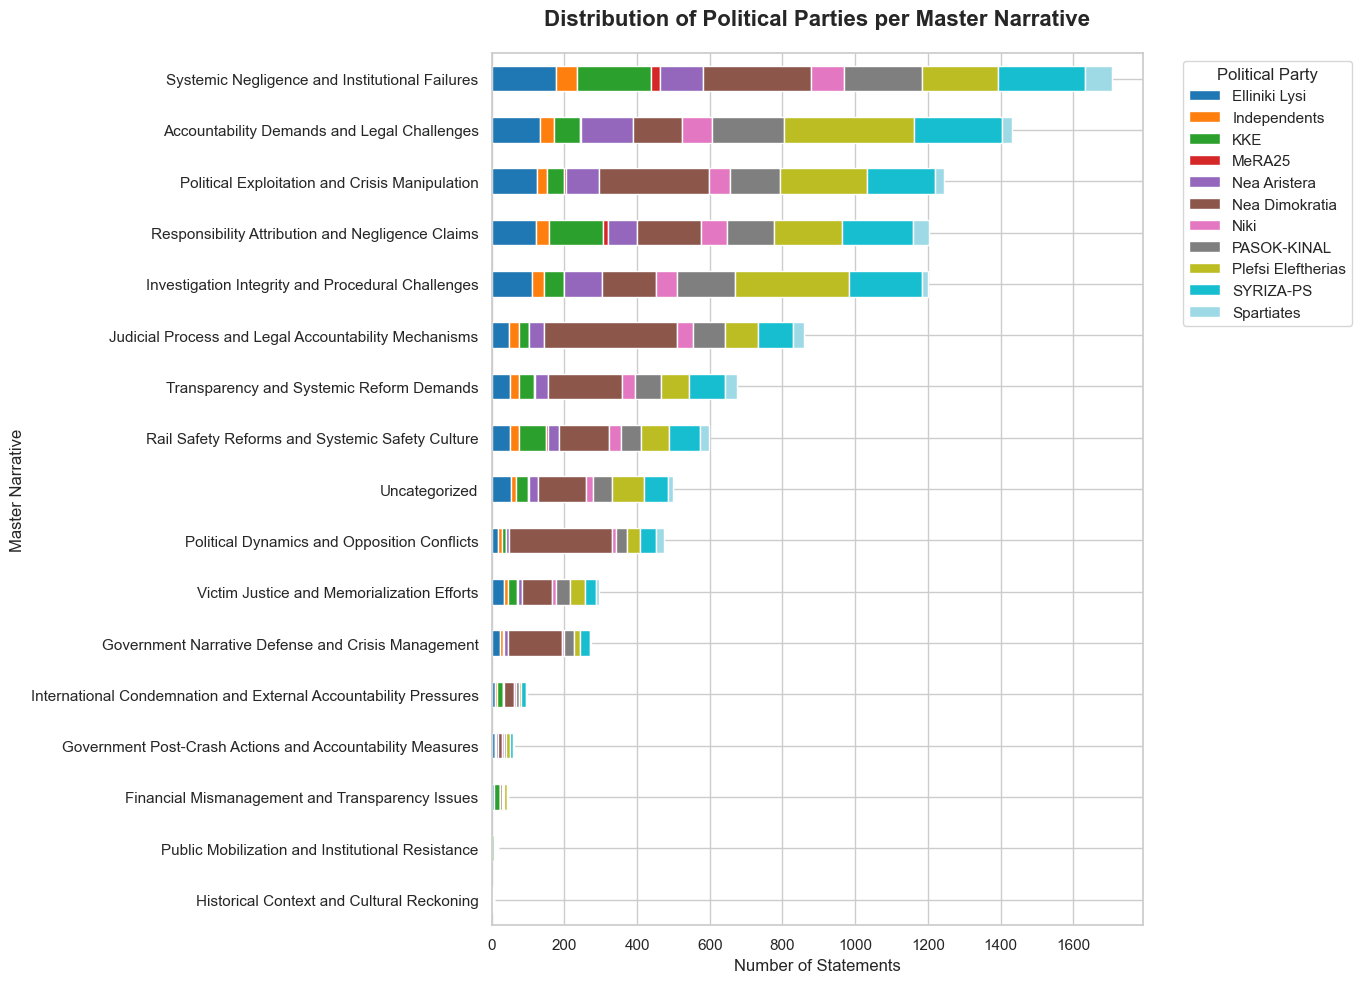


Generating individual charts per Master Narrative...


C:\Users\thomt\AppData\Local\Temp\ipykernel_21252\1650460982.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_data.values, y=cat_data.index, palette='viridis', orient='h')


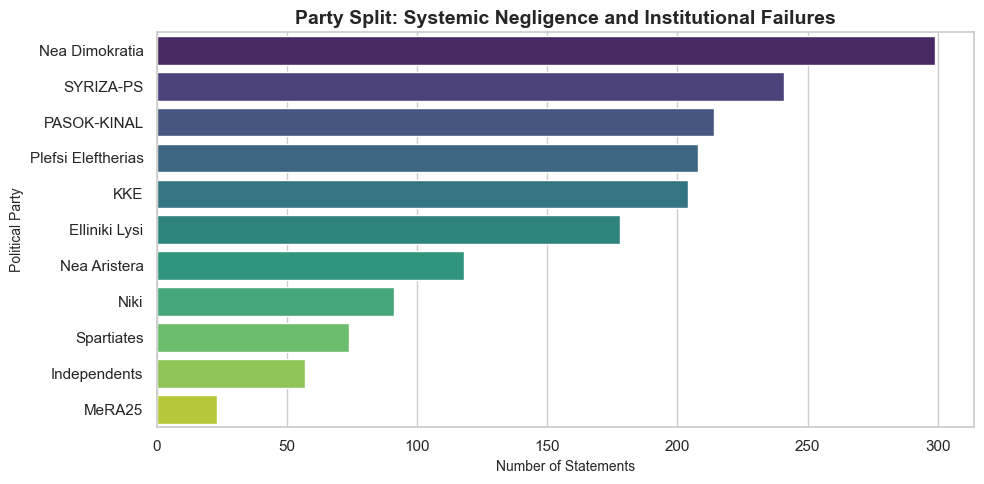

C:\Users\thomt\AppData\Local\Temp\ipykernel_21252\1650460982.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_data.values, y=cat_data.index, palette='viridis', orient='h')


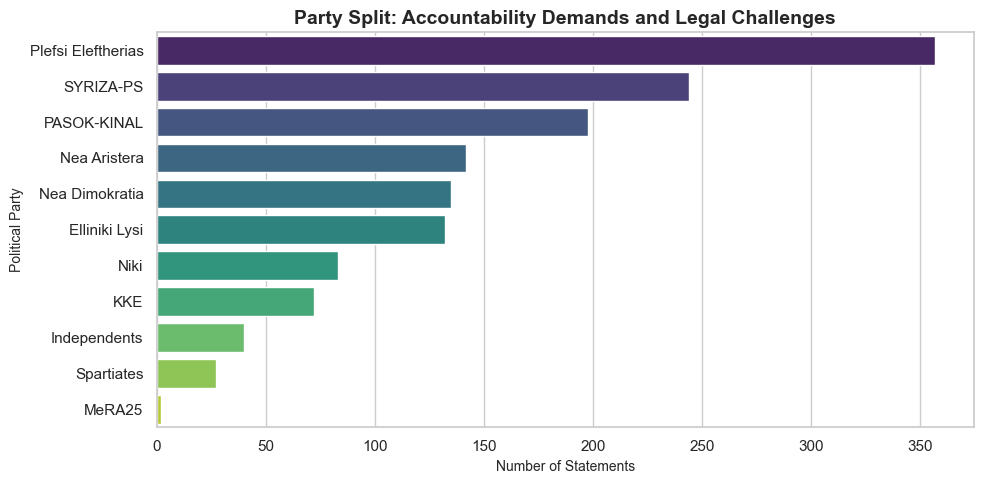

C:\Users\thomt\AppData\Local\Temp\ipykernel_21252\1650460982.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_data.values, y=cat_data.index, palette='viridis', orient='h')


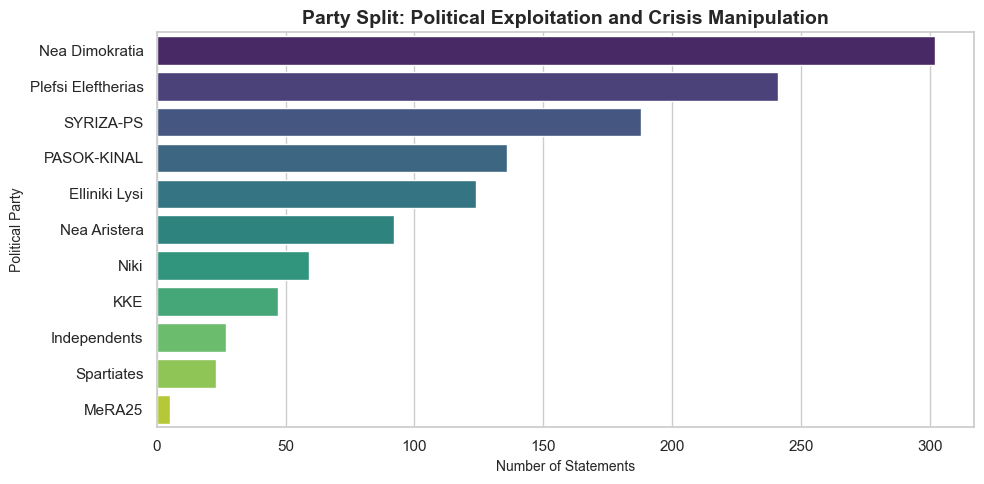

C:\Users\thomt\AppData\Local\Temp\ipykernel_21252\1650460982.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_data.values, y=cat_data.index, palette='viridis', orient='h')


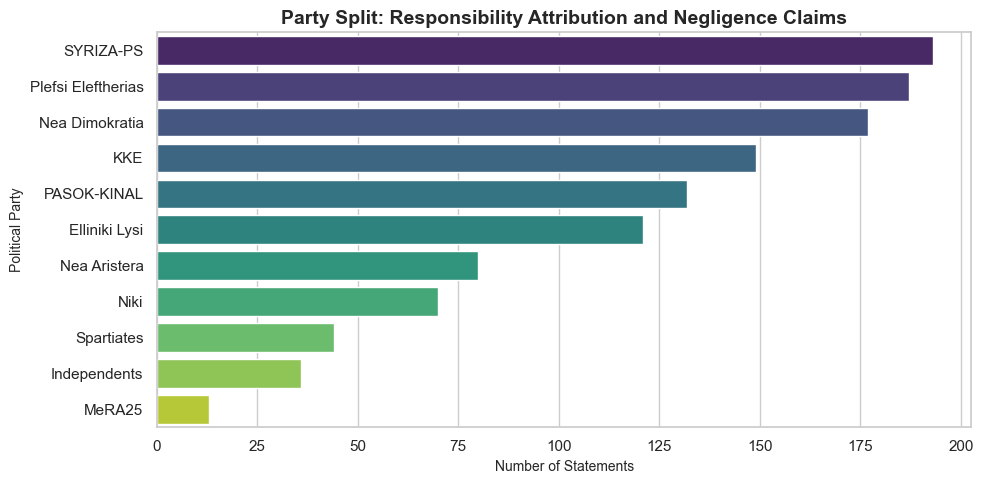

C:\Users\thomt\AppData\Local\Temp\ipykernel_21252\1650460982.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_data.values, y=cat_data.index, palette='viridis', orient='h')


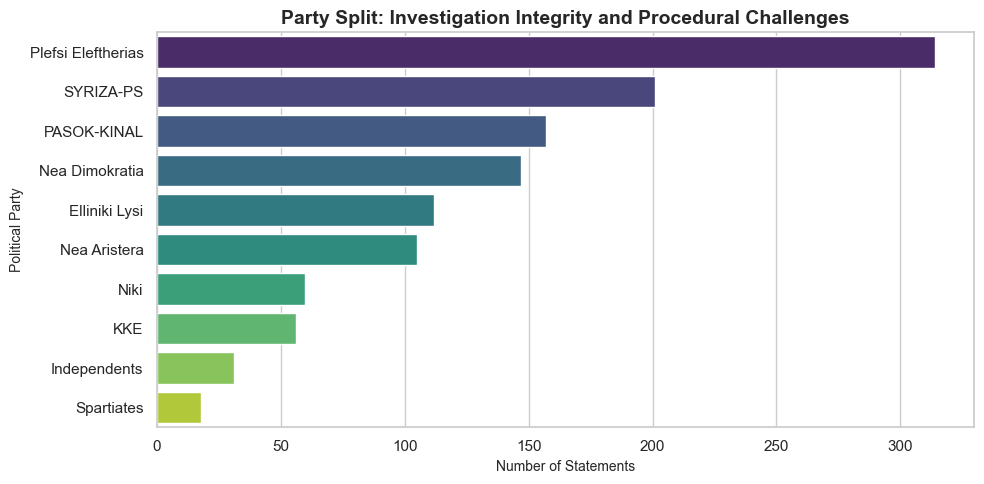

C:\Users\thomt\AppData\Local\Temp\ipykernel_21252\1650460982.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_data.values, y=cat_data.index, palette='viridis', orient='h')


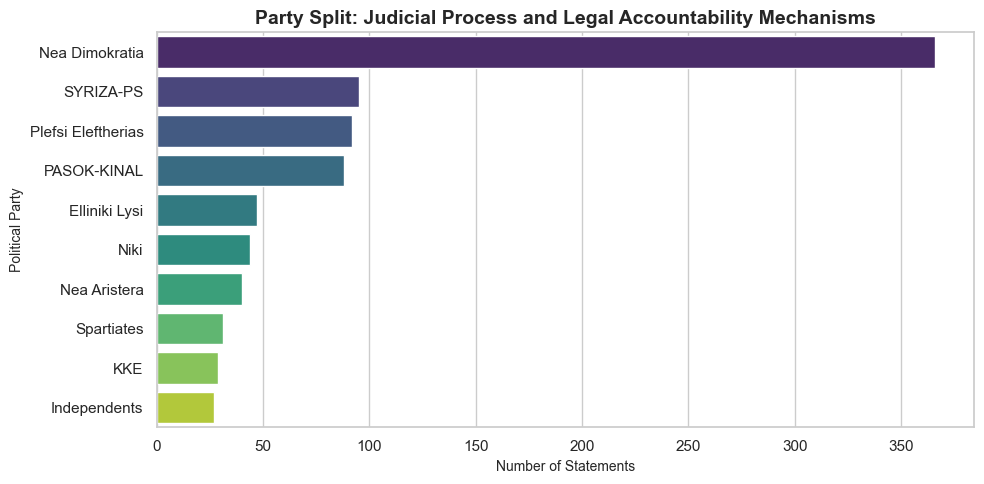

C:\Users\thomt\AppData\Local\Temp\ipykernel_21252\1650460982.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_data.values, y=cat_data.index, palette='viridis', orient='h')


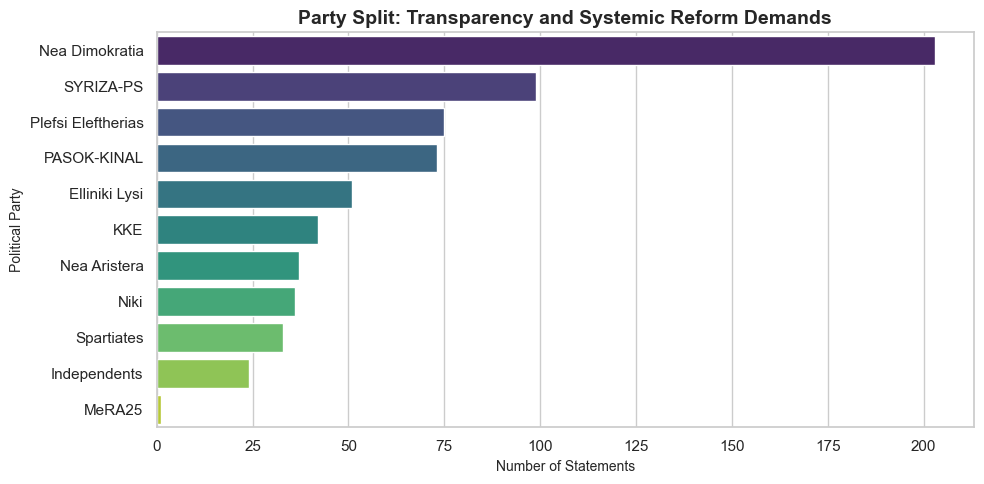

C:\Users\thomt\AppData\Local\Temp\ipykernel_21252\1650460982.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_data.values, y=cat_data.index, palette='viridis', orient='h')


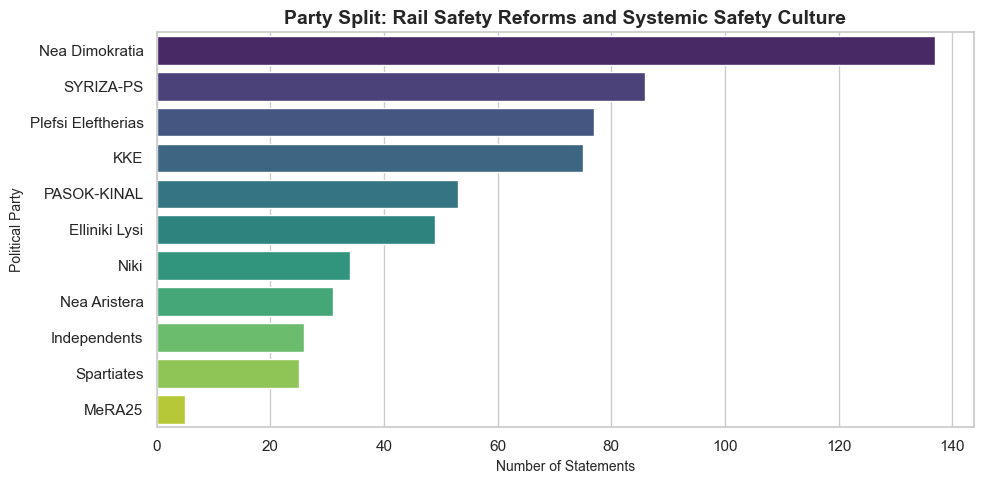

C:\Users\thomt\AppData\Local\Temp\ipykernel_21252\1650460982.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_data.values, y=cat_data.index, palette='viridis', orient='h')


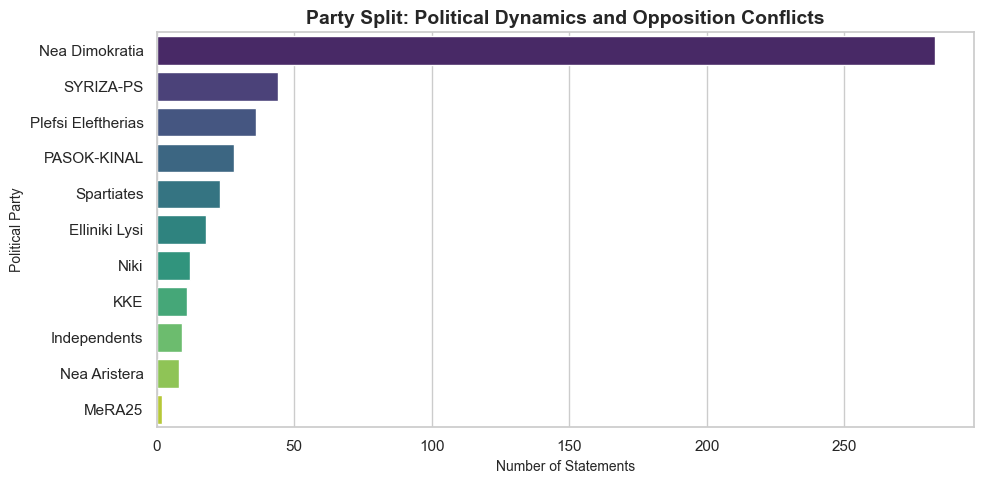

C:\Users\thomt\AppData\Local\Temp\ipykernel_21252\1650460982.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_data.values, y=cat_data.index, palette='viridis', orient='h')


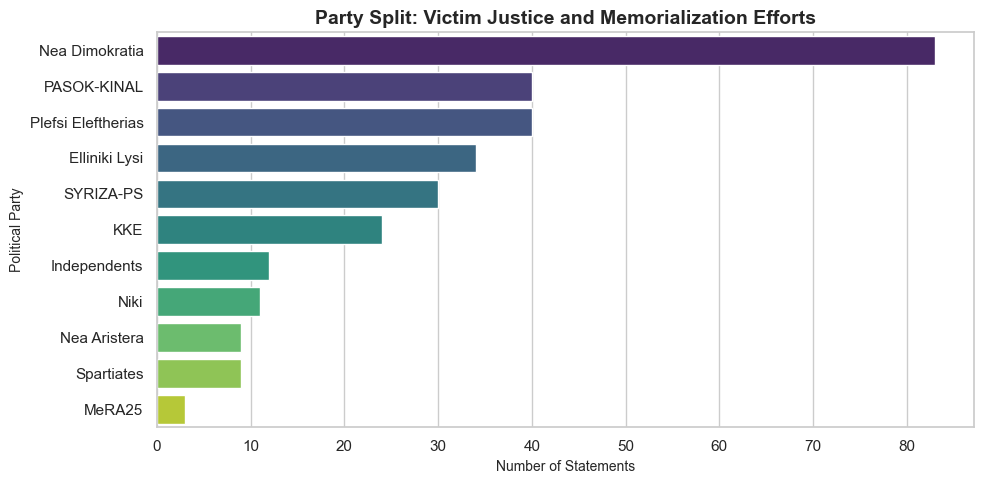

C:\Users\thomt\AppData\Local\Temp\ipykernel_21252\1650460982.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_data.values, y=cat_data.index, palette='viridis', orient='h')


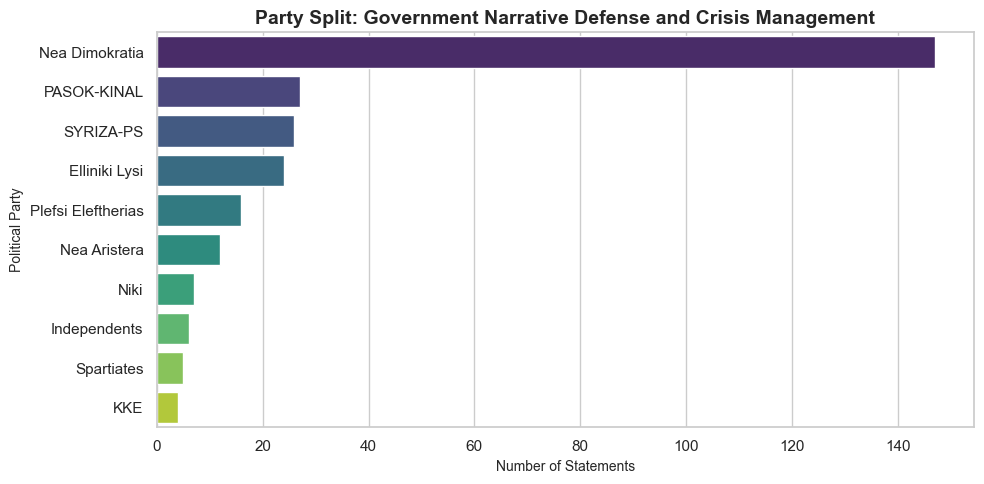

C:\Users\thomt\AppData\Local\Temp\ipykernel_21252\1650460982.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_data.values, y=cat_data.index, palette='viridis', orient='h')


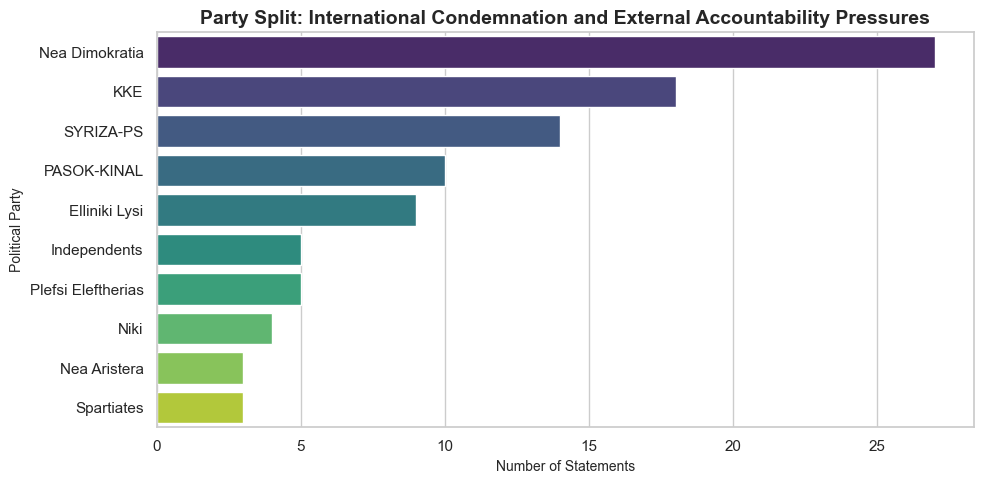

C:\Users\thomt\AppData\Local\Temp\ipykernel_21252\1650460982.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_data.values, y=cat_data.index, palette='viridis', orient='h')


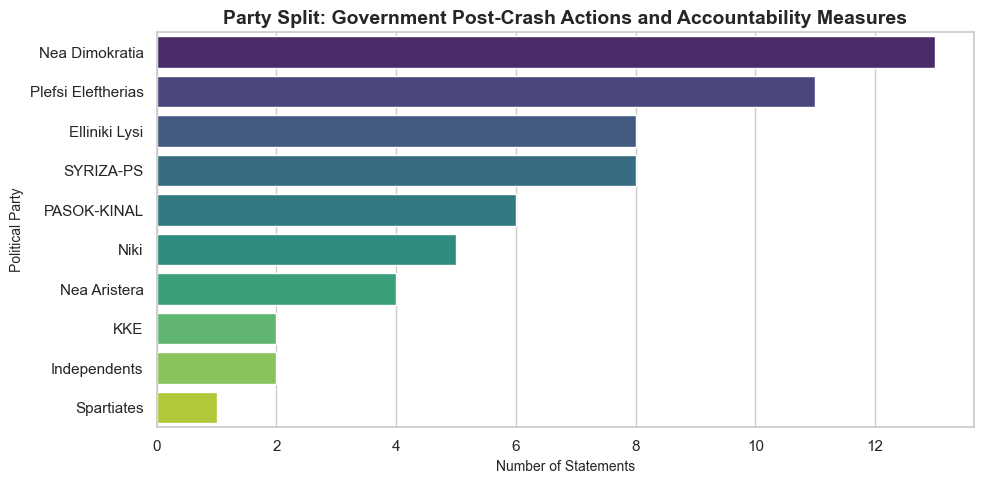

C:\Users\thomt\AppData\Local\Temp\ipykernel_21252\1650460982.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_data.values, y=cat_data.index, palette='viridis', orient='h')


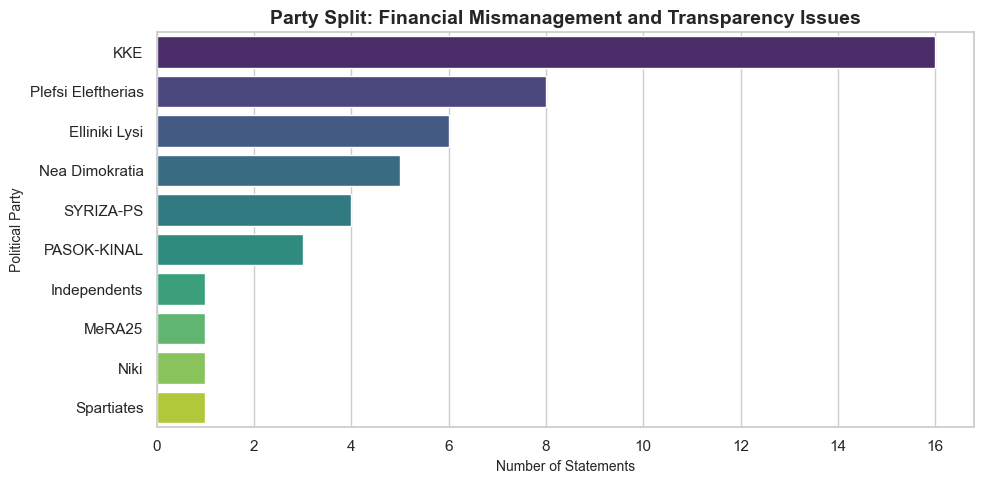

C:\Users\thomt\AppData\Local\Temp\ipykernel_21252\1650460982.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_data.values, y=cat_data.index, palette='viridis', orient='h')


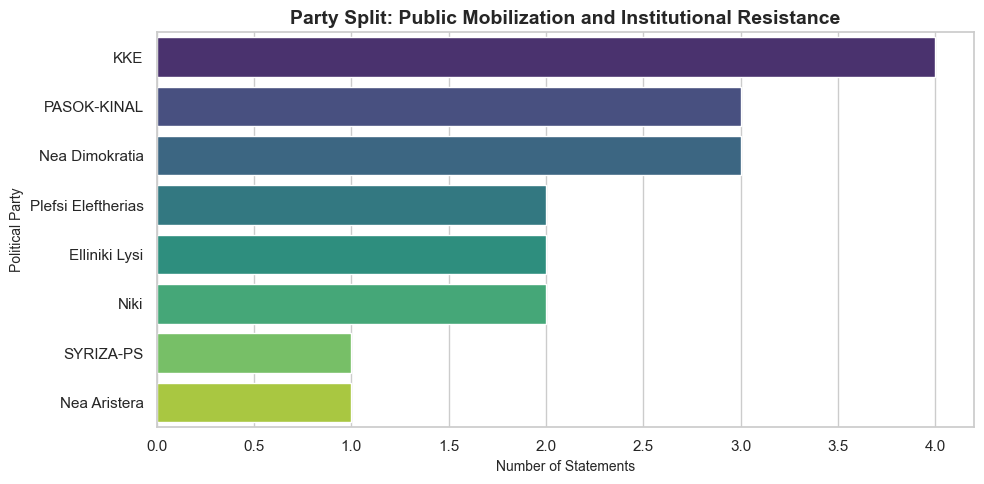

C:\Users\thomt\AppData\Local\Temp\ipykernel_21252\1650460982.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_data.values, y=cat_data.index, palette='viridis', orient='h')


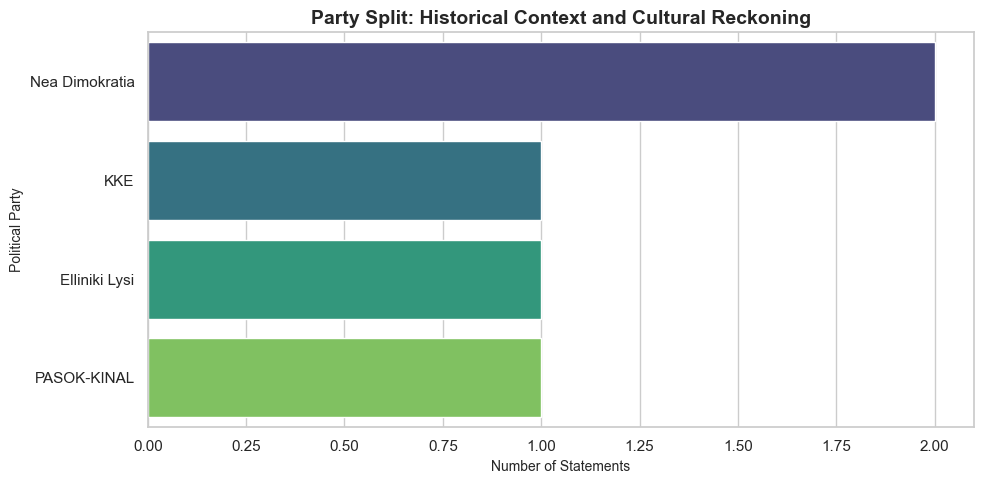

In [129]:
df_extracted =pd.read_csv('./llm_full_pipeline/02_pipeline_classified_dataframe_R1.csv', encoding='utf-8-sig')

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the fully classified dataset
df = pd.read_csv('./llm_full_pipeline/02_pipeline_classified_dataframe_R1.csv', encoding='utf-8-sig')

# Clean up any missing party data just in case
df['political_party'] = df['political_party'].fillna('Unknown')

# Create a cross-tabulation of Narratives vs. Political Parties
party_narrative_counts = pd.crosstab(df['narrative_category'], df['political_party'])

# Sort the categories by total volume so the biggest narratives appear first
party_narrative_counts['Total'] = party_narrative_counts.sum(axis=1)
party_narrative_counts = party_narrative_counts.sort_values(by='Total', ascending=True).drop(columns='Total')

# Set visual style
sns.set_theme(style="whitegrid")

# ==========================================
# OPTION 1: ALL-IN-ONE STACKED BAR CHART
# ==========================================
print("Generating comprehensive stacked bar chart...")

# Plotting
ax = party_narrative_counts.plot(
    kind='barh', 
    stacked=True, 
    figsize=(14, 10), 
    colormap='tab20'
)

plt.title('Distribution of Political Parties per Master Narrative', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Number of Statements', fontsize=12)
plt.ylabel('Master Narrative', fontsize=12)
plt.legend(title='Political Party', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


# ==========================================
# OPTION 2: INDIVIDUAL CHARTS PER NARRATIVE
# ==========================================
print("\nGenerating individual charts per Master Narrative...")

# We reverse the order here so the biggest narratives print first in the notebook
sorted_categories = party_narrative_counts.iloc[::-1].index.tolist()

for category in sorted_categories:
    # Skip 'Uncategorized' if you want to keep the output clean
    if category == 'Uncategorized':
        continue
        
    # Get the data for this specific category and sort the parties by count
    cat_data = party_narrative_counts.loc[category].sort_values(ascending=False)
    cat_data = cat_data[cat_data > 0] # Drop parties that didn't use this narrative
    
    plt.figure(figsize=(10, 5))
    sns.barplot(x=cat_data.values, y=cat_data.index, palette='viridis', orient='h')
    
    plt.title(f'Party Split: {category}', fontsize=14, fontweight='bold')
    plt.xlabel('Number of Statements', fontsize=10)
    plt.ylabel('Political Party', fontsize=10)
    plt.tight_layout()
    plt.show()



In [123]:
taxonomy_df = pd.read_csv('./llm_full_pipeline/03_pipeline_taxonomy_mapping_R1.csv', encoding='utf-8-sig')
# prints a list of the narratives per master category
for _, row in taxonomy_df.iterrows():
    print(f"{row['narrative_category']}:")
    for narrative in row['narratives_list'].splitlines():
        print(f"  - {narrative}")


Accountability Demands and Legal Challenges:
  - - Political interference in crash investigation undermines judicial independence.
  - - The Tempi tragedy was a political crime demanding accountability over legislative procedures
  - - Former minister bears criminal responsibility and must exit politics.
  - - Immediate infrastructure upgrades and accountability are essential to prevent future tragedies.
  - - Political interference directed judicial handling of crash investigation.
  - - Justice and railway safety reforms are demanded following the preventable tragedy.
  - - The parliament must uphold solemnity and responsibility amid the tragedy.
  - - Government insincerely apologized while suppressing demands for truth and accountability.
  - - Criminal negligence and cover-up attempts followed the disaster.
  - - The Tempi tragedy demands justice, answers, and accountability for the victims.
  - - Government accepts responsibility, investigates causes, and upgrades railway safety 

### Standalone narrative families

In [ ]:
# --- JSON EXTRACTOR ---
def extract_json_from_model_output(text: str):
    if not text or not isinstance(text, str):
        return None
    text = re.sub(r"<think>.*?</think>", "", text, flags=re.DOTALL)
    text = re.sub(r"```json", "", text, flags=re.IGNORECASE)
    text = re.sub(r"```", "", text)
    start = text.find('{')
    end = text.rfind('}')
    if start != -1 and end != -1 and end > start:
        candidate = text[start:end+1]
        try:
            return json.loads(candidate)
        except Exception:
            pass
    return None

In [ ]:
import os
import re
import json
import time
import pandas as pd
import boto3


def get_user_prompt(item_count, text_block):
    return f"""Act like a senior political discourse analyst and qualitative annotation specialist with expertise in political narratives, interpretive framing, and semantic clustering.

Your goal is to organize individual political narrative statements about the Tempi train crash in Greece into coherent narrative families, following the conceptual definition provided below.

Task: Read the complete list of {item_count} unique narrative statements and identify distinct narrative families that capture recurring interpretations of the political issue.

Definition and conceptual framework:
A political narrative is a recurring, overt or implicit claim that promotes a particular interpretation of an ongoing political issue. 
A narrative statement is a concise claim about the Tempi crash, its causes, responsibility, the investigation, or its broader political interpretation. 
A narrative family is a group of semantically related statements expressing a recurring interpretive frame.

Context:
The Tempi train crash refers to the fatal train collision near Tempi, Greece, on 28 February 2023, and its political, legal, and institutional aftermath, including railway safety, investigation, accountability, compensation, infrastructure, and ministerial responsibility.

Inputs:
<<<NARRATIVES_START
{text_block}
NARRATIVES_END>>>

Step-by-step instructions:

1. Read every narrative statement in the input before forming categories. 
Treat each statement as an expression of a claim or interpretation, rather than merely a mention of a topic, person, institution, or event.

2. Identify recurring interpretive frames across statements. 
Examine the meanings they convey about causes, responsibility, intentions, institutional conduct, accountability, proposed solutions, and the broader political significance of the crash.

3. Group statements into the same narrative family when they share a substantive underlying interpretation, 
even if they differ in wording, specificity, emotional tone, explicitness, or named actors. Recognize both overt claims and implicit framing when supported by the statements.

4. Distinguish narrative families by their central interpretive claim, not merely by shared keywords or subject matter. 
For example, statements about the investigation may belong to different families if one alleges deliberate government obstruction while another emphasizes institutional incompetence.

5. Create a separate family for a meaningfully distinct recurring frame. 
Avoid splitting semantically equivalent claims into redundant categories, but do not merge claims that imply different causes, responsibilities, intentions, or political interpretations.

6. Base categories exclusively on the supplied statements. 
Do not introduce external assumptions, unsupported motives, or claims absent from the input. Do not create miscellaneous, residual, or mixed categories.

7. Give each family a concise, informative English title of 4–8 words that expresses its shared interpretive claim. 
Prefer specific, analytical wording over broad topic labels. Avoid titles that merely name an issue, institution, or actor without conveying the frame.

8. Review all titles for semantic distinctiveness, consistency, and redundancy. 
Ensure that each title represents a coherent interpretive frame and that the final categories collectively capture the recurring narratives in the input without unnecessary duplication.

Output constraints:
- Language: English only.
- Format: Return a single valid JSON object with exactly one key, "categories", containing an array of strings.
- Each string must be one narrative-family title of 4–8 words.
- Include no explanations, individual narrative statements, counts, confidence scores, or additional keys.
- Do not include Markdown fences or any text outside the JSON object.
- Ensure the JSON is syntactically valid and all titles are concise, declarative, and analytically meaningful.

Take a deep breath and work on this problem step-by-step."""

# 1. Load the extracted narratives
df_extracted = pd.read_csv('./llm_full_pipeline/01_pipeline_extracted_narratives.csv', encoding='utf-8-sig')

# 2. Clean and deduplicate
raw_narratives = df_extracted['narrative'].dropna().tolist()
all_unique_narratives = list(set([n.strip() for n in raw_narratives if n.strip(" .\"'").lower() != "irrelevant"]))

print(f"Total extracted records: {len(df_extracted)}")
print(f"Total UNIQUE narratives: {len(all_unique_narratives)}")

# --- PHASE 1: BATCH PROCESSING (MAP) ---
CHUNK_SIZE = 1500
intermediate_categories = []

def chunk_list(lst, n):
    for i in range(0, len(lst), n):
        yield lst[i:i + n]

chunks = list(chunk_list(all_unique_narratives, CHUNK_SIZE))
print(f"\nPhase 1: Processing {len(chunks)} chunks of ~{CHUNK_SIZE} narratives to find sub-categories...")

for chunk_idx, chunk in enumerate(chunks):
    print(f"Processing chunk {chunk_idx + 1}/{len(chunks)}...")
    
    # Format exactly as you requested: "- {text}"
    chunk_text = "\n".join([f"- {text}" for text in chunk])
    
    # Generate your exact prompt
    prompt_chunk = get_user_prompt(len(chunk), chunk_text)
    
    try:
        response = bedrock_runtime.converse(
            modelId="us.deepseek.r1-v1:0", 
            messages=[{"role": "user", "content": [{"text": prompt_chunk}]}],
            inferenceConfig={"maxTokens": 8192}
        )
        
        model_reply = response["output"]["message"]["content"][0]["text"]
        parsed = extract_json_from_model_output(model_reply)
        
        if parsed and "categories" in parsed:
            cats = parsed["categories"]
            intermediate_categories.extend(cats)
            print(f"  -> Found {len(cats)} sub-categories.")
        else:
            print(f"  -> Failed to parse JSON for chunk {chunk_idx + 1}.")
            
    except Exception as e:
        print(f"  -> Error on chunk {chunk_idx + 1}: {e}")
        
    time.sleep(1)

# Remove exact duplicates from the intermediate list
intermediate_categories = list(set(intermediate_categories))
print(f"\nPhase 1 Complete. Found {len(intermediate_categories)} unique intermediate sub-categories.")

# --- PHASE 2: FINAL SYNTHESIS (REDUCE) ---
print("\nPhase 2: Synthesizing final overarching narrative families...")

# Format the intermediate categories exactly as you requested
final_text_block = "\n".join([f"- {cat}" for cat in intermediate_categories])

# Generate your exact prompt one last time to cluster the sub-categories
prompt_final = get_user_prompt(len(intermediate_categories), final_text_block)

try:
    response = bedrock_runtime.converse(
        modelId="us.deepseek.r1-v1:0", 
        messages=[{"role": "user", "content": [{"text": prompt_final}]}],
        inferenceConfig={"maxTokens": 8192}
    )

    model_reply = response["output"]["message"]["content"][0]["text"]
    parsed_final = extract_json_from_model_output(model_reply)

    if parsed_final and "categories" in parsed_final:
        final_taxonomy = parsed_final["categories"]
        
        print("\n--- Final Discovered Taxonomy ---")
        for i, cat in enumerate(final_taxonomy, 1):
            print(f"{i}. {cat}")
            
        df_taxonomy = pd.DataFrame({
            "category_id": range(1, len(final_taxonomy) + 1), 
            "category": final_taxonomy
        })
        df_taxonomy.to_csv('./llm_full_pipeline/02_pipeline_taxonomy_R1.csv', index=False, encoding='utf-8-sig')
        print("\nSuccess! Final taxonomy saved to './llm_full_pipeline/02_pipeline_taxonomy.csv'")
    else:
        print("\nFailed to parse final JSON.")

except Exception as e:
    print(f"Error during final taxonomy synthesis: {e}")

Total extracted records: 10686
Total UNIQUE narratives: 10647

Phase 1: Processing 8 chunks of ~1500 narratives to find sub-categories...
Processing chunk 1/8...
  -> Found 20 sub-categories.
Processing chunk 2/8...
  -> Found 25 sub-categories.
Processing chunk 3/8...
  -> Found 15 sub-categories.
Processing chunk 4/8...
  -> Found 30 sub-categories.
Processing chunk 5/8...
  -> Found 20 sub-categories.
Processing chunk 6/8...
  -> Found 20 sub-categories.
Processing chunk 7/8...
  -> Found 15 sub-categories.
Processing chunk 8/8...
  -> Found 13 sub-categories.

Phase 1 Complete. Found 154 unique intermediate sub-categories.

Phase 2: Synthesizing final overarching narrative families...

--- Final Discovered Taxonomy ---
1. Privatization and profit prioritization compromising rail safety
2. Systemic negligence and chronic underfunding enabling disaster
3. Government cover-up and obstruction of investigation
4. Judicial interference shielding political accountability
5. Scapegoating l